# Шаг 8 (бонус). Анализатор текста

Соберём все модели сессии в один инструмент. Это и есть то, как готовые модели используют на практике:
не одна «умная» модель на всё, а **несколько** маленьких, каждая для своей задачи.

| Что узнаём | Модель | Шаг |
|-----------|--------|-----|
| жанр | rubert-tiny2 + наша голова | 4 |
| тон, эмоции | готовые классификаторы | 2 |
| похожие отрывки | векторы смысла | 3 |
| неожиданные слова | ruGPT-3 | 6 |
| краткий пересказ | Qwen 0.5B | 7 |

Загрузка всех моделей занимает около минуты. Пересказ от чат-бота — самая медленная часть, её можно выключить (`USE_CHAT = False`).

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

In [2]:
import os

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

from common import HERE, Embedder, load_genres, load_model, load_tokenizer, model_dir, show
from transformers import pipeline     # после common: там отключены лишние предупреждения

USE_CHAT = True          # пересказ от Qwen: самая медленная часть, можно выключить

RU = {"neutral": "нейтрально", "positive": "позитив", "negative": "негатив",
      "no_emotion": "без эмоций", "joy": "радость", "sadness": "грусть", "surprise": "удивление",
      "fear": "страх", "anger": "злость"}

print("Загружаем модели...")
embed = Embedder()
sentiment = pipeline("text-classification", model=str(model_dir("sentiment")), top_k=None)
emotions = pipeline("text-classification", model=str(model_dir("emotion")), top_k=None)
gpt_tok, gpt = load_tokenizer("gpt"), load_model("gpt", "lm")
if USE_CHAT:
    chat_tok, chat_model = load_tokenizer("chat"), load_model("chat", "lm")

# --- голова жанров из шага 4 (если её нет — быстро обучаем такую же)
rows = load_genres()
corpus = [r["text"] for r in rows]
corpus_vectors = embed(corpus)
if (HERE / "genre_head.pt").exists():
    saved = torch.load(HERE / "genre_head.pt")
    GENRES, SCALE = saved["genres"], saved["scale"]
    head = nn.Linear(312, len(GENRES))
    head.load_state_dict(saved["state"])
    print("Голова жанров загружена из genre_head.pt")
else:
    print("Нет genre_head.pt (шаг 4) — обучаем голову жанров заново, это несколько секунд")
    GENRES, SCALE = list(dict.fromkeys(r["genre"] for r in rows)), 10
    train = [i for i, r in enumerate(rows) if r["split"] == "train"]
    X, y = corpus_vectors[train], torch.tensor([GENRES.index(rows[i]["genre"]) for i in train])
    head = nn.Linear(312, len(GENRES))
    opt = torch.optim.Adam(head.parameters(), lr=0.003, weight_decay=1e-3)
    for _ in range(200):
        loss = F.cross_entropy(head(SCALE * X), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
print("Готово!")

Загружаем модели...


Голова жанров загружена из genre_head.pt
Готово!


## Функции анализа

Каждая функция — несколько строк из соответствующего шага сессии.

In [3]:
@torch.no_grad()
def analyze_genre(text):
    probs = torch.softmax(head(SCALE * embed(text)), dim=-1)[0]
    return {g: p for g, p in zip(GENRES, probs.tolist())}


def analyze_mood(text):
    tone = {RU[r["label"]]: r["score"] for r in sentiment(text, truncation=True)[0]}
    emo = {RU[r["label"]]: r["score"] for r in emotions(text, truncation=True)[0]}
    return tone, emo


def similar(text, k=3):
    scores = (embed(text) @ corpus_vectors.T)[0]
    best = scores.topk(k)
    return [(s, rows[i]["genre"], corpus[i]) for s, i in zip(best.values.tolist(), best.indices.tolist())]


@torch.no_grad()
def surprising_words(text, k=5):
    """Самые неожиданные для ruGPT-3 слова (кусочки одного слова склеиваем; первые 4 токена пропускаем)."""
    ids = gpt_tok(text, return_tensors="pt", truncation=True, max_length=1024)["input_ids"]
    logp = gpt(ids).logits[0, :-1].log_softmax(-1)
    s = (-logp[torch.arange(ids.shape[1] - 1), ids[0, 1:]]).tolist()
    words = []                                         # (слово, суммарное удивление)
    for i, token in enumerate(ids[0, 1:].tolist()):
        piece = gpt_tok.decode([token])
        if piece[:1] in (" ", "\n") or not words:      # токен с пробелом или переводом строки — новое слово
            words.append([piece, s[i], i])
        else:
            words[-1][0] += piece
            words[-1][1] += s[i]
    words = [(w.strip(" \n,.!?;:—«»\"()"), v) for w, v, i in words if i >= 3 and any(ch.isalpha() for ch in w)]
    return sorted(words, key=lambda t: -t[1])[:k]


@torch.no_grad()
def summarize(text):
    messages = [{"role": "system", "content": "Перескажи текст одним коротким предложением по-русски."},
                {"role": "user", "content": text}]
    prompt = chat_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    ids = chat_tok(prompt, return_tensors="pt")["input_ids"]
    out = chat_model.generate(ids, max_new_tokens=60, do_sample=False, temperature=None, top_p=None, top_k=None,
                              pad_token_id=chat_tok.eos_token_id)
    return chat_tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True).strip()


def analyze(text, plot=True):
    genre = analyze_genre(text)
    tone, emo = analyze_mood(text)
    print("=" * 70)
    print(text[:300] + ("…" if len(text) > 300 else ""))
    print("-" * 70)
    best = sorted(genre, key=genre.get, reverse=True)
    print("Жанр:      ", ", ".join(f"{g} {genre[g]:.0%}" for g in best[:3]))
    print("Тон:       ", ", ".join(f"{k} {v:.0%}" for k, v in sorted(tone.items(), key=lambda t: -t[1])))
    print("Эмоции:    ", ", ".join(f"{k} {v:.0%}" for k, v in sorted(emo.items(), key=lambda t: -t[1]) if v > 0.15) or "—")
    print("Неожиданные слова:", ", ".join(f"«{w}» ({v:.0f})" for w, v in surprising_words(text)))
    print("Похожие отрывки из genres.csv:")
    for s, g, t in similar(text):
        print(f"   {s:.2f} [{g}] {t[:80]}…")
    if USE_CHAT:
        print("Пересказ от Qwen:", summarize(text))

    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
        for ax, data, title, color in [(axes[0], genre, "жанр", "tab:blue"), (axes[1], tone, "тон", "tab:green"),
                                       (axes[2], emo, "эмоции (у каждой своя вероятность)", "tab:red")]:
            names = sorted(data, key=data.get)
            ax.barh(names, [data[n] for n in names], color=color)
            ax.set_xlim(0, 1)
            ax.set_title(title)
        fig.suptitle(text[:80] + ("…" if len(text) > 80 else ""), fontsize=10)
        plt.tight_layout()
        show()

## Пробуем

Вставьте в `TEXT` свой текст: сочинение, пост, отрывок из книги, слова песни — и запустите ячейку.

Мы все учились понемногу
Чему-нибудь и как-нибудь,
Так воспитаньем, слава богу,
У нас немудрено блеснуть.
----------------------------------------------------------------------
Жанр:       сказка 79%, стихи 15%, научпоп 5%
Тон:        позитив 71%, нейтрально 25%, негатив 4%
Эмоции:     радость 94%
Неожиданные слова: «воспитаньем» (20), «Чему-нибудь» (19), «немудрено» (12), «блеснуть» (9), «слава» (7)
Похожие отрывки из genres.csv:
   0.64 [сказка] Жили-были в одной норке три мышонка. Старший был храбрый, средний хитрый, а млад…
   0.63 [сказка] В некотором царстве, в некотором государстве жил царь, и было у него три сына. М…
   0.61 [стихи] Я помню вечер у реки,
Где ивы низко наклонились,
И как печальны и легки
Над нами…


Пересказ от Qwen: Нам было много учиться, что-то искать, чтобы быть хорошей.


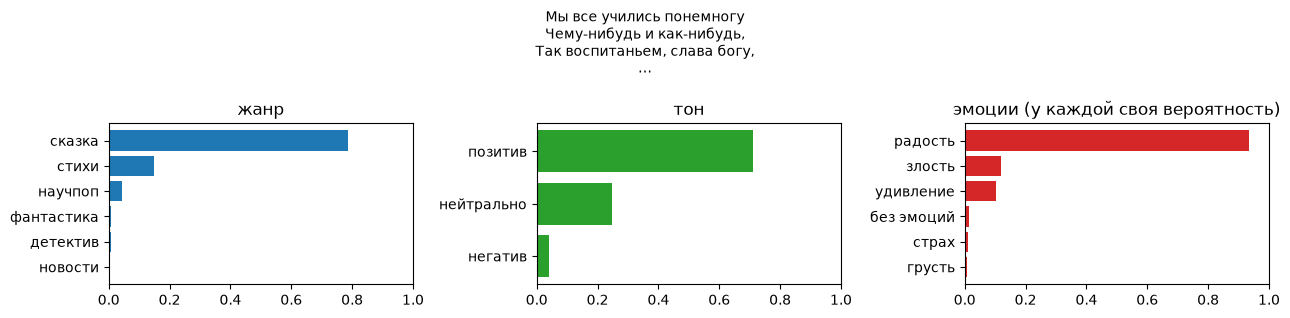

In [4]:
TEXT = """Мы все учились понемногу
Чему-нибудь и как-нибудь,
Так воспитаньем, слава богу,
У нас немудрено блеснуть."""
analyze(TEXT)

Вчера наша школьная команда заняла первое место на городском турнире по робототехнике. Робот, которого мы собирали полгода, прошёл всю трассу без единой ошибки!
----------------------------------------------------------------------
Жанр:       новости 49%, фантастика 37%, сказка 8%
Тон:        нейтрально 51%, позитив 43%, негатив 6%
Эмоции:     без эмоций 98%
Неожиданные слова: «Робот» (13), «прошёл» (7), «полгода» (7), «трассу» (7), «ошибки» (7)
Похожие отрывки из genres.csv:
   0.63 [фантастика] Экипаж проснулся из анабиоза на сто лет раньше срока. Бортовой компьютер молчал,…
   0.63 [новости] В понедельник в столице прошло заседание городской думы. Депутаты утвердили бюдж…
   0.62 [фантастика] Терраформирование Венеры заняло триста лет. Первые дома на её поверхности постро…


Пересказ от Qwen: Сегодня наша команда заняла второе место в городском турнире по робототехнике. Робот, который мы собрали за полгода, прошёл всю трассу без ошибок!


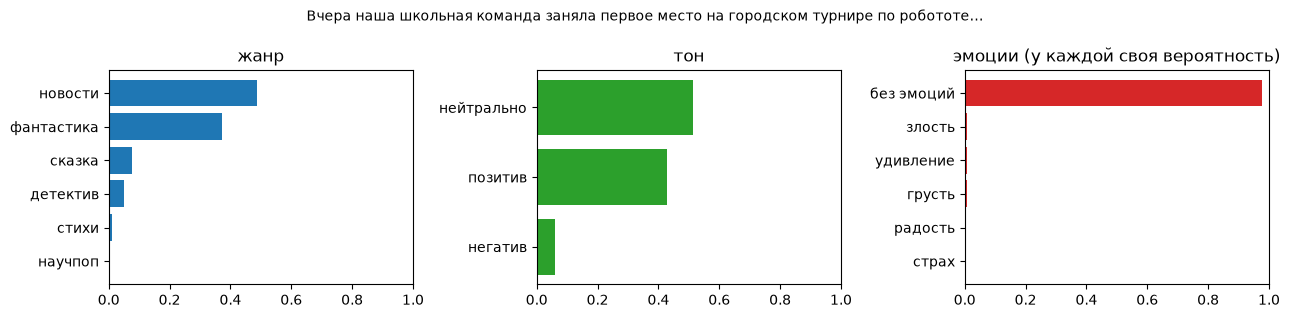

In [5]:
analyze("Вчера наша школьная команда заняла первое место на городском турнире по робототехнике. "
        "Робот, которого мы собирали полгода, прошёл всю трассу без единой ошибки!")

**Не верьте анализатору на слово.** Посмотрите внимательно на результаты:
- строфу Пушкина голова жанров может принять за сказку — BERT не видит строк (шаг 4, пункт 8);
- сравните пересказ Qwen с исходным текстом: маленький чат-бот может переврать факт (например, «первое место» → «второе»);
- «неожиданные» слова — это не обязательно ошибки: устаревшее «воспитаньем» или редкое «немудрено» просто редко встречаются в текстах.

## Мини-проект

Выберите задачу и сделайте из анализатора свой инструмент. Идеи:

1. **«Кардиограмма» книги** (как в шаге 2): тон и жанр по главам любимой книги или по куплетам песни.
2. **Анализ сочинения:** самые неожиданные слова часто оказываются опечатками или удачными находками — проверьте своё сочинение.
3. **Сортировщик отзывов:** соберите 20 отзывов о фильме или игре, разложите их по тону и найдите самые похожие друг на друга.
4. **Новый жанр:** добавьте в `genres.csv` жанр «песня» или «рецепт», переобучите голову в шаге 4 и проверьте анализатор.
5. **Честное сравнение:** придумайте 10 текстов-«ловушек» (сарказм, смешанный жанр, опечатки) и посчитайте,
   сколько из них модели разбирают правильно. Какая модель ошибается чаще всего?

На защите проекта покажите, где модели справились и где ошиблись, и объясните **почему** — по тому, что узнали за сессию.